In [1]:
import matplotlib.pyplot as plt
import numpy as np

In [2]:
org_density_matrix = np.load('org_density_matrix.npy')
density_matrix1 = np.load('density_matrix.npy')

In [3]:
chemical_range = np.linspace(-20, 4, 25)
kbt_range  = np.linspace(1, 13, 25)

matrix = density_matrix1
diff = org_density_matrix[:25,:25] - matrix

/Users/suemin/opt/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:38: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


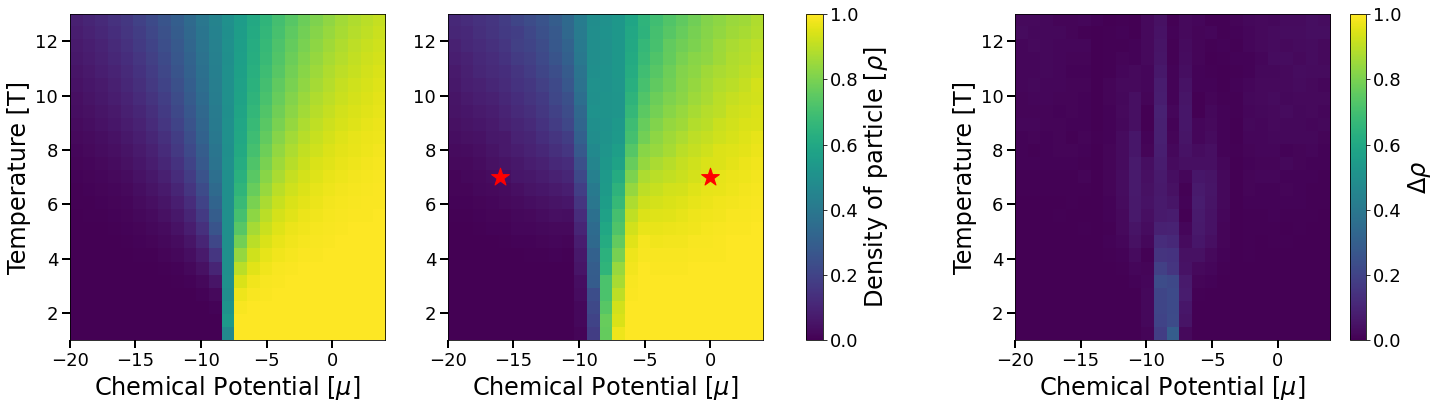

In [4]:

# Create the figure
fig, axes = plt.subplots(1, 3, figsize=(24, 6), gridspec_kw={'width_ratios': [1, 1, 1], 'wspace': .2})

# Subplot 1
im1 = axes[0].imshow(org_density_matrix[:25, :25], aspect='auto', origin='lower',
                     extent=[chemical_range.min(), chemical_range.max(),
                             kbt_range.min(), kbt_range.max()], cmap='viridis')
axes[0].set_xlabel(r'Chemical Potential [$\mu$]', fontsize=24)
axes[0].set_ylabel('Temperature [T]', fontsize=24)
axes[0].tick_params(axis='both', which='major', length=8, width=2, labelsize=18)

# Subplot 2
im2 = axes[1].imshow(matrix, aspect='auto', origin='lower',
                     extent=[chemical_range.min(), chemical_range.max(),
                             kbt_range.min(), kbt_range.max()], cmap='viridis')
axes[1].scatter([-16, 0], [7, 7], color='red', marker='*', s=350)
axes[1].set_xlabel(r'Chemical Potential [$\mu$]', fontsize=24)
axes[1].tick_params(axis='both', which='major', length=8, width=2, labelsize=18)

# Shared colorbar for subplots 1 and 2
cbar = fig.colorbar(im1, ax=axes[:2], location='right')#, shrink=0.95)
cbar.set_label(label=r'Density of particle [$\rho$]', size=24)
cbar.ax.tick_params(labelsize=18)

# Subplot 3
im3 = axes[2].imshow(np.abs(diff), aspect='auto', origin='lower',
                     extent=[chemical_range.min(), chemical_range.max(),
                             kbt_range.min(), kbt_range.max()], cmap='viridis', vmin=0, vmax=1)
axes[2].set_ylabel('Temperature [T]', fontsize=24)
axes[2].set_xlabel(r'Chemical Potential [$\mu$]', fontsize=24)
axes[2].tick_params(axis='both', which='major', length=8, width=2, labelsize=18)

# Separate colorbar for subplot 3
cbar3 = fig.colorbar(im3, ax=axes[2], location='right')#, shrink=0.8, pad=0.1)
cbar3.set_label(label=r'$\Delta\rho$', size=24)
cbar3.ax.tick_params(labelsize=18)

plt.tight_layout()
plt.savefig('ising_density_subplots_org.pdf')
plt.show()